# IND320 – Compulsory work, part 3

- GitHub: https://github.com/maryanahmed11011-pixel/IND320.prosjekt.maryan
- Streamlit app: https://ind320prosjektmaryan-lmvbjxajmrnrqkykq8ivne.streamlit.app/
   - Screencast: https://github.com/maryanahmed11011-pixel/IND320-screencasts/blob/main/screencast_del3.mp4 
This notebook builds on parts 1 and 2. It downloads ERA5 weather data
for the Norwegian price areas (NO1–NO5) and precipitation areas
(VASS1–3), and analyses outliers, anomalies, seasonal-trend
decomposition and spectrograms of reservoir filling.

##  AI usage

I used an AI assistant (Claude) throughout part 3, mainly in four ways:

- **Debugging:** finding the cause of errors, e.g. missing VASS points
  for the app (a save cell that overwrote the data), rate limiting from
  open-meteo, an indentation error that broke the deployed app, and Git
  problems when merging branches.
- **Understanding the methods:** how the DCT works as a high-pass
  filter, why robust statistics (median and MAD) suit SPC, how LOF finds
  local anomalies, and how STL and spectrogram parameters affect the
  results.
- **Writing and structuring code:** the AI suggested first versions of
  several functions and Streamlit pages, which I then ran, tested,
  adjusted and simplified. It also helped me reorganise the notebook.
- **Design:** a shared colour palette (`theme.py`), the app theme, the
  donut chart and short explanations on the analysis pages.

I checked all results myself by running the code, comparing plots with
the data and testing the app locally and online. Interpretations and
choices (e.g. which NVE layers to use and how to map them to VASS areas)
were discussed with the AI but decided and verified by me.

## Log

Part 3 extended the project from reservoir data to weather data, and
added time series methods for outliers, anomalies and seasonality.

**Finding the right areas.** The most difficult part was finding the
correct areas in NVE Atlas. The price areas (NO1–NO5) were easy to find
under Nettanlegg > Nettområder > Budområder, but the layer could not be
downloaded directly from the menu. I therefore fetched it as GeoJSON from
NVE's map service, which is also more reproducible. The precipitation
areas took longer: the catchment layers under Vassdrag were far too
detailed. I finally found the layer NVE_Region under Administrasjon, with
the codes RØ, RS, RV, RM and RN. By combining RØ+RS and RM+RN as the
assignment says, I got three areas. I matched them to VASS1–3 in
Magasinstatistikk by comparing reservoir capacity, which added up to the
total for Norway.

**Downloading weather data.** Sampling 1000 points per area gave far more
locations than the free open-meteo API allows. Since ERA5 has a
resolution of about 25 km, many points fall in the same grid cell, so I
snapped the points to the ERA5 grid and removed duplicates. For NO3 this
gave 313 grid cells. I also added caching and automatic retries when the
API was rate limited. In the app I use 20 grid cells per area, so the
numbers differ slightly from the notebook.

**The analyses.** The assignment text mixes precipitation and
temperature for SPC, so I followed it literally and applied SPC to
precipitation. All outliers lie above the upper limit, since
precipitation is strongly skewed. LOF on temperature values alone marked
ordinary temperatures, so I fitted it on both time and temperature
instead, which found abrupt changes compared with the surrounding days.
STL and the spectrogram clearly show the annual cycle of the reservoirs.

**Keeping the code tidy.** Another challenge was keeping the notebook
and the app organised as they grew. A cell that saved the sampled points
before the VASS areas were added made the app fail for VASS1, which
taught me how important cell order is for *Restart & Run All*. I moved
the shared analysis functions to `analysis.py` and the colours to
`theme.py`, so the notebook and the app use the same methods and style.
The sampled points are stored in MongoDB instead of a CSV file.

**Streamlit.** I chose one global area selector in the sidebar that
controls the reservoir data, the weather download and the default
connection on the cross-border page. The weather data is downloaded in
the background and cached, so no separate download page is needed. I
also improved the design with a common blue theme and short explanations
on each analysis page. Finally, an indentation error broke the deployed
app, which showed me the value of testing before merging to main.

In [1]:
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy.fft import dct, idct
from scipy.signal import spectrogram
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

ERA5_URL = "https://archive-api.open-meteo.com/v1/archive"
RES_URL = ("https://biapi.nve.no/magasinstatistikk/api/"
           "Magasinstatistikk/HentOffentligData")
HOURLY_VARS = ["temperature_2m", "precipitation",
               "wind_speed_10m", "relative_humidity_2m"]
SEED = 42  # fixed seed so the random sampling is reproducible

## 1. Areas from NVE

Two area types are used, matching Magasinstatistikk:
- **Price areas (EL, NO1–NO5):** atlas.nve.no > Nettanlegg >
  Nettområder > Budområder.
- **Precipitation areas (VASS1–3):** atlas.nve.no > Administrasjon >
  Administrative områder > NVE_Region. Following the assignment,
  East = RØ + RS and North = RM + RN; West = RV. The VASS numbering
  is inferred from reservoir capacity (see section 6).


Both layers are fetched as GeoJSON from NVE's map services and cached.
The same layers can be downloaded manually as shapefiles from
atlas.nve.no. Fetching them from NVE's map service gives the same
data and makes the notebook reproducible without manual downloads.

In [2]:
def load_geojson(url, file):
    """Download a GeoJSON layer once, then reuse the local copy."""
    if file.exists():
        return gpd.read_file(file)
    gdf = gpd.read_file(url)
    gdf.to_file(file, driver="GeoJSON")
    return gdf


QUERY = "/MapServer/0/query?where=1%3D1&outFields=*&outSR=4326&f=geojson"

# Price areas: names come as "NO 1" ... -> "NO1"
areas = load_geojson(
    "https://kart.nve.no/enterprise/rest/services/Nettomraader" + QUERY,
    DATA_DIR / "budomrader.geojson",
)
areas["region"] = areas["budomr"].str.replace(" ", "", regex=False)

# NVE regions mapped to the VASS areas in Magasinstatistikk
REGION_TO_VASS = {
    "RØ": "VASS1", "RS": "VASS1",  # East
    "RV": "VASS2",                 # West
    "RM": "VASS3", "RN": "VASS3",  # North
}
nve_regions = load_geojson(
    "https://gis3.nve.no/map/rest/services/Mapservices/Administrasjon2"
    + QUERY,
    DATA_DIR / "nve_regions.geojson",
)
nve_regions["region"] = nve_regions["REGION"].map(REGION_TO_VASS)
nve_regions[["REGION", "REGIONNAVN", "region"]]

,REGION,REGIONNAVN,region
0,RV,Region Vest,VASS2
1,RM,Region Midt-Norge,VASS3
2,RN,Region Nord,VASS3
3,RØ,Region Øst,VASS1
4,RS,Region Sør,VASS1


## 2. Random sampling of locations

1000 random points are sampled inside each area. Sampling is done in a
metric CRS (UTM 33N), so the points are uniform per km². Polygons are
dissolved first, so RØ + RS and RM + RN become one area each. Some
points fall offshore, since the price area polygons extend into the
sea. The points are stored in MongoDB, where the Streamlit app reads
them (so no CSV file is needed in the repository).

In [3]:
def sample_locations(gdf, area_col="region", n=1000, seed=SEED):
    """Sample n random points inside each area -> region, lon, lat."""
    gdf_m = gdf.dissolve(by=area_col).reset_index().to_crs(epsg=25833)
    frames = []
    for region, geom in zip(gdf_m[area_col], gdf_m.geometry):
        pts = gpd.GeoSeries([geom], crs=gdf_m.crs).sample_points(n, rng=seed)
        pts = pts.explode(index_parts=False).to_crs(epsg=4326)
        frames.append(pd.DataFrame(
            {"region": region, "lon": pts.x.values, "lat": pts.y.values}
        ))
    return pd.concat(frames, ignore_index=True)


# Both area types in one table
LOCATIONS = pd.concat(
    [sample_locations(areas), sample_locations(nve_regions)],
    ignore_index=True,
)
LOCATIONS["region"].value_counts().sort_index()  # 1000 per area

region
NO1      1000
NO2      1000
NO3      1000
NO4      1000
NO5      1000
VASS1    1000
VASS2    1000
VASS3    1000
Name: count, dtype: int64

In [4]:
# Store the points in MongoDB for the Streamlit app. The connection
# string is read from the app's secrets file, so it is not in the code.
SECRETS = "../.streamlit/secrets.toml"
try:                       # Python 3.11+
    import tomllib
    with open(SECRETS, "rb") as f:
        mongo_uri = tomllib.load(f)["mongo"]["uri"]
except ModuleNotFoundError:  # Python 3.10: toml comes with Streamlit
    import toml
    mongo_uri = toml.load(SECRETS)["mongo"]["uri"]

from pymongo import MongoClient

loc_col = MongoClient(mongo_uri)["ind320"]["locations"]
loc_col.delete_many({})                              # replace old points
loc_col.insert_many(LOCATIONS.to_dict("records"))
print(loc_col.count_documents({}), "locations stored in MongoDB")

8000 locations stored in MongoDB


## 3. ERA5 download from open-meteo

Points are snapped to the ERA5 grid (~0.25°) and duplicates removed,
since many points fall in the same ~25 km cell. This reduces the
number of API calls without losing information. Data is cached as CSV,
and the function waits and retries if the free API is rate limited.

In [5]:
def snap_to_era5_grid(locs, res=0.25):
    """Round points to the ERA5 grid and drop duplicates."""
    snapped = locs.assign(lat=(locs["lat"] / res).round() * res,
                          lon=(locs["lon"] / res).round() * res)
    return snapped.drop_duplicates(["lat", "lon"]).reset_index(drop=True)


def _get_with_retry(params, retries=5):
    """GET request that waits and retries if rate limited (HTTP 429)."""
    for attempt in range(retries):
        r = requests.get(ERA5_URL, params=params, timeout=120)
        if r.status_code == 429:
            print(f"Rate limited, waiting {60 * (attempt + 1)} s ...")
            time.sleep(60 * (attempt + 1))
            continue
        r.raise_for_status()
        return r.json()
    raise RuntimeError("Too many retries against open-meteo")


def download_era5(region, start, end, hourly=HOURLY_VARS,
                  batch_size=50, max_points=None):
    """Download hourly ERA5 data for one region ("NO3", "VASS1" ...).

    start, end : dates as "YYYY-MM-DD"
    max_points : optional cap on the number of ERA5 grid cells
    Returns a long DataFrame: one row per location and hour.
    """
    cache = DATA_DIR / f"era5_{region}_{start}_{end}.csv"
    if cache.exists():
        return pd.read_csv(cache, parse_dates=["time"])

    # Look up the sampled points for this region
    locs = snap_to_era5_grid(LOCATIONS[LOCATIONS["region"] == region])
    if max_points and len(locs) > max_points:
        locs = locs.sample(max_points, random_state=SEED)
    print(f"{region}: {len(locs)} unique ERA5 grid cells")

    frames = []
    for i in range(0, len(locs), batch_size):
        batch = locs.iloc[i:i + batch_size]
        data = _get_with_retry({
            "latitude": ",".join(f"{v:.4f}" for v in batch["lat"]),
            "longitude": ",".join(f"{v:.4f}" for v in batch["lon"]),
            "start_date": start, "end_date": end,
            "hourly": ",".join(hourly), "models": "era5",
            "timezone": "GMT",  # UTC avoids DST gaps/duplicates
        })
        data = [data] if isinstance(data, dict) else data
        for j, loc in enumerate(data):
            df = pd.DataFrame(loc["hourly"])
            df["time"] = pd.to_datetime(df["time"])
            df["location_id"] = i + j
            frames.append(df)
        time.sleep(1)  # be polite to the free API

    out = pd.concat(frames, ignore_index=True)
    out.insert(0, "region", region)
    out.to_csv(cache, index=False)
    return out

In [6]:
no3 = download_era5("NO3", "2024-01-01", "2024-12-31")

# Regional average over all locations, used in the analyses below
no3_mean = no3.groupby("time")[HOURLY_VARS].mean()

# Check: 2024 is a leap year -> 8784 hours
print(len(no3_mean), "hours,", no3["location_id"].nunique(), "grid cells")
no3_mean.head()

8784 hours, 313 grid cells


,temperature_2m,precipitation,wind_speed_10m,relative_humidity_2m
time,,,,
2024-01-01 00:00:00,-3.745367,0.004473,25.032588,70.290735
2024-01-01 01:00:00,-3.875399,0.003834,25.303514,70.322684
2024-01-01 02:00:00,-3.846965,0.003514,25.587540,69.853035
2024-01-01 03:00:00,-3.879553,0.003514,25.676997,69.492013
2024-01-01 04:00:00,-3.825879,0.003195,25.875719,69.233227


## 4. Outliers with SPC on seasonally adjusted variations (DCT)

Following the assignment, the average precipitation is high-pass
filtered with the Discrete Cosine Transform: components with a period
longer than `cutoff_days` are removed, giving seasonally adjusted
variations (SATV). SPC boundaries are set at median ± `n_std` · robust
SD (MAD × 1.4826) of the SATV, and added back to the low-frequency
trend so they follow the original curve. Only the original series,
the boundaries and the outliers are plotted.

In [7]:
def spc_outliers(series, cutoff_days=30, n_std=3.0, label=None):
    """SPC outliers based on DCT high-pass filtered data.

    series      : hourly values with a DatetimeIndex
    cutoff_days : periods longer than this are treated as seasonal
    n_std       : number of robust SDs for the boundaries
    Returns (fig, summary dict, outliers DataFrame).
    """
    x = series.to_numpy(dtype=float)

    # DCT coefficient k has period ~ 2n/k hours: keep low frequencies
    coefs = dct(x, norm="ortho")
    coefs[int(np.ceil(2 * len(x) / (cutoff_days * 24))):] = 0
    trend = idct(coefs, norm="ortho")
    satv = x - trend  # seasonally adjusted variations

    # Robust boundaries from the whole year, added back to the trend
    med = np.median(satv)
    robust_sd = 1.4826 * np.median(np.abs(satv - med))
    upper = trend + med + n_std * robust_sd
    lower = trend + med - n_std * robust_sd
    is_out = (x > upper) | (x < lower)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, x, lw=0.6, label="Data")
    ax.plot(series.index, upper, "--", lw=1, color="grey",
            label=f"SPC limits (±{n_std} SD)")
    ax.plot(series.index, lower, "--", lw=1, color="grey")
    ax.scatter(series.index[is_out], x[is_out], s=8, color="tab:red",
               zorder=3, label="Outliers")
    ax.set(ylabel=label, title=f"SPC outliers – {label}")
    ax.legend(loc="upper right")
    fig.tight_layout()

    outliers = pd.DataFrame({"value": x[is_out], "lower": lower[is_out],
                             "upper": upper[is_out]},
                            index=series.index[is_out])
    summary = {
        "n_outliers": int(is_out.sum()),
        "share_%": round(float(100 * is_out.mean()), 2),
        "n_above": int((x > upper).sum()),
        "n_below": int((x < lower).sum()),
        "robust_sd": round(float(robust_sd), 3),
    }
    return fig, summary, outliers

{'n_outliers': 632, 'share_%': 7.19, 'n_above': 632, 'n_below': 0, 'robust_sd': 0.151}


,value,lower,upper
time,,,
2024-01-12 20:00:00,0.691054,-0.347478,0.559782
2024-01-12 21:00:00,0.910224,-0.346812,0.560448
2024-01-12 22:00:00,1.052716,-0.346144,0.561116
2024-01-12 23:00:00,1.184026,-0.345475,0.561785
2024-01-13 00:00:00,1.211821,-0.344804,0.562456


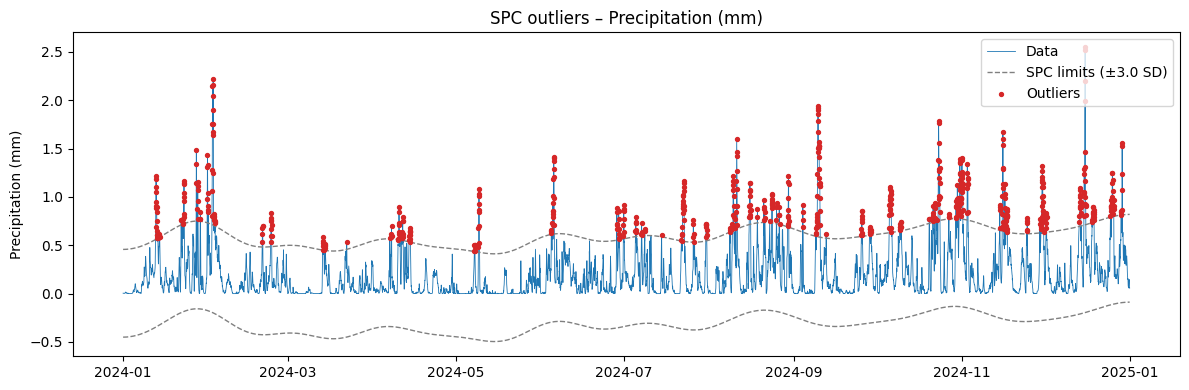

In [8]:
fig, summary, outliers = spc_outliers(no3_mean["precipitation"],
                                      label="Precipitation (mm)")
print(summary)
outliers.head()

**Interpretation:** All 632 outliers (7.2 %) lie above the upper limit.
Precipitation is strongly right-skewed: most hours have little or no
rain, while a few events are intense. The robust SD is therefore small,
and heavy-rain events exceed the limit, typically for several hours in
a row. The lower limit is below zero and has no physical meaning, so no
outliers are found below it. A larger `n_std` gives fewer outliers.

## 5. Anomalies in temperature with Local Outlier Factor (LOF)

LOF compares the local density around each observation with the
density around its nearest neighbours. Fitting LOF on temperature
values alone flagged ordinary temperatures (e.g. 9 °C in summer),
since it ignores when they occurred. LOF is therefore fitted on
(time, temperature), with time in days, so that an hour is anomalous
if it deviates from the surrounding days. The expected proportion of
anomalies (`contamination`) defaults to 1 %.

In [9]:
def lof_anomalies(series, contamination=0.01, n_neighbors=20,
                  time_scale=24, label=None):
    """LOF anomalies fitted on (time, value).

    contamination : expected proportion of anomalies
    n_neighbors   : number of neighbours used by LOF
    time_scale    : hours per time unit (24: one day weighs as much as
                    one unit of the variable)
    Returns (fig, summary dict, anomalies DataFrame).
    """
    x = series.to_numpy(dtype=float)
    t = (series.index - series.index[0]) / pd.Timedelta(hours=time_scale)
    features = np.column_stack([np.asarray(t, dtype=float), x])

    lof = LocalOutlierFactor(n_neighbors=n_neighbors,
                             contamination=contamination)
    is_anom = lof.fit_predict(features) == -1  # -1 = anomaly
    scores = -lof.negative_outlier_factor_      # higher = more anomalous

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, x, lw=0.6, label="Data")
    ax.scatter(series.index[is_anom], x[is_anom], s=10, color="tab:red",
               zorder=3, label=f"LOF anomalies ({contamination:.1%})")
    ax.set(ylabel=label, title=f"LOF anomalies – {label}")
    ax.legend(loc="upper right")
    fig.tight_layout()

    anomalies = pd.DataFrame({"value": x[is_anom],
                              "lof_score": scores[is_anom]},
                             index=series.index[is_anom])
    summary = {
        "n_anomalies": int(is_anom.sum()),
        "share_%": round(float(100 * is_anom.mean()), 2),
        "min_value": round(float(x[is_anom].min()), 2),
        "max_value": round(float(x[is_anom].max()), 2),
    }
    return fig, summary, anomalies

{'n_anomalies': 88, 'share_%': 1.0, 'min_value': -7.52, 'max_value': 19.2}


,value,lof_score
time,,
2024-01-20 16:00:00,-5.807348,2.473498
2024-01-20 15:00:00,-6.711502,2.422485
2024-01-20 14:00:00,-6.999361,2.187072
2024-01-20 13:00:00,-7.056550,2.121275
2024-12-24 07:00:00,0.711182,2.109757


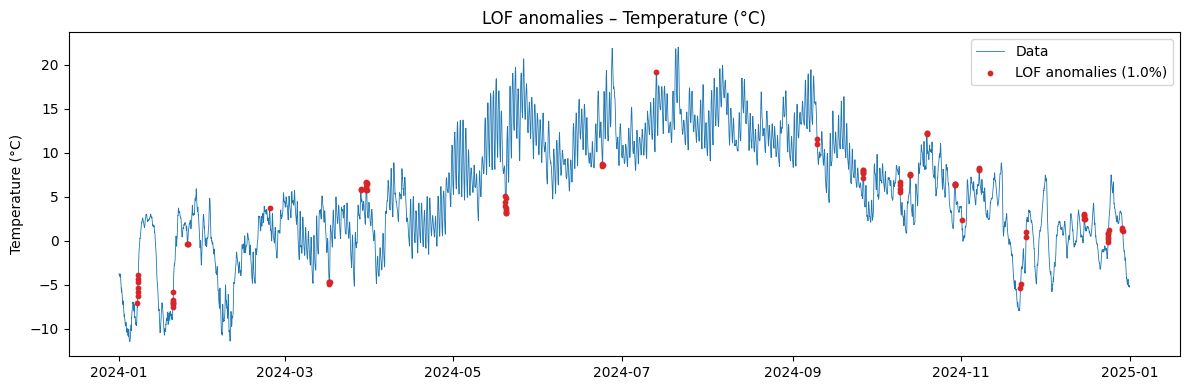

In [10]:
fig, summary, anomalies = lof_anomalies(no3_mean["temperature_2m"],
                                        label="Temperature (°C)")
print(summary)
anomalies.sort_values("lof_score", ascending=False).head()

**Interpretation:** With (time, temperature) as features, the 88
anomalies (1 %) cluster around abrupt temperature changes relative to
the surrounding days, e.g. the cold spell on 20 January and the sudden
drop around 20 May. The anomalies come in groups of consecutive hours,
since such events last for several hours. Fitting on temperature alone
(tested first) instead flagged ordinary values in sparse parts of the
distribution, which was less meaningful.

## 6. Reservoir filling degree from Magasinstatistikk

The same NVE API as in the Streamlit app is used. Weekly filling degree
for price area NO3 is used in the STL and spectrogram analyses, so it
matches the weather data above. The VASS capacities are also shown,
since they were used to match the NVE regions to VASS1–3.

In [11]:
RES_FILE = DATA_DIR / "magasinstatistikk.csv"

# Download once, then reuse the local copy (same column names as the app)
if RES_FILE.exists():
    res = pd.read_csv(RES_FILE, parse_dates=["date"])
else:
    r = requests.get(RES_URL, timeout=30)
    r.raise_for_status()
    res = pd.DataFrame(r.json()).rename(columns={
        "dato_Id": "date", "omrType": "area_type", "omrnr": "area_number",
        "fyllingsgrad": "filling_degree", "kapasitet_TWh": "capacity_TWh",
        "fylling_TWh": "filling_TWh",
    })
    res["date"] = pd.to_datetime(res["date"])
    res.to_csv(RES_FILE, index=False)

# Weekly filling degree for price area NO3
filling_no3 = (res[(res["area_type"] == "EL") & (res["area_number"] == 3)]
               .set_index("date")["filling_degree"].sort_index())

# VASS capacities: 1 ≈ 36 TWh (East), 2 ≈ 23 (West), 3 ≈ 28 (North)
res[res["area_type"] == "VASS"].groupby("area_number")["capacity_TWh"].max()

area_number
1    36.044464
2    23.237715
3    28.155403
Name: capacity_TWh, dtype: float64

## 7. Seasonal-Trend decomposition using LOESS (STL)

STL splits the weekly filling degree into trend, seasonal and residual
components. The period is 52 weeks. The seasonal and trend smoothers
(odd window lengths) and robust fitting are parameters.

In [12]:
def stl_decompose(series, period=52, seasonal=13, trend=105,
                  robust=False, label=None):
    """STL decomposition of a weekly series. Returns a figure.

    seasonal : seasonal smoother length (odd, >= 7)
    trend    : trend smoother length (odd, > period); 105 weeks ≈ 2 years
    robust   : robust fitting, less sensitive to outliers
    """
    fit = STL(series, period=period, seasonal=seasonal,
              trend=trend, robust=robust).fit()

    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    parts = [(series, "Observed"), (fit.trend, "Trend"),
             (fit.seasonal, "Seasonal"), (fit.resid, "Residual")]
    for ax, (data, name) in zip(axes, parts):
        ax.plot(data.index, data, lw=0.8)
        ax.set_ylabel(name)
    axes[0].set_title(f"STL – {label} (seasonal={seasonal}, "
                      f"trend={trend}, robust={robust})")
    fig.tight_layout()
    return fig

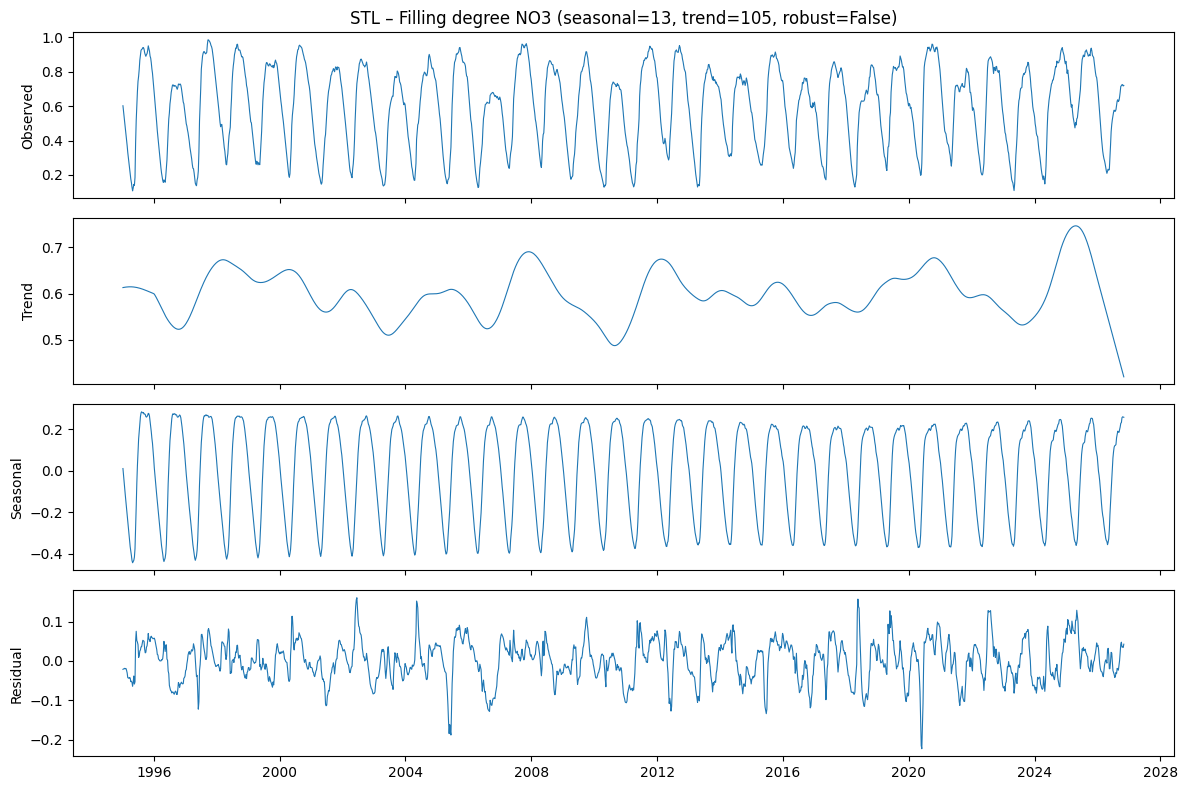

In [13]:
fig = stl_decompose(filling_no3, label="Filling degree NO3")

**Interpretation:** The seasonal component dominates, with an amplitude
of about ±0.3: reservoirs are lowest in spring before snowmelt and
highest in autumn. The trend varies between roughly 0.5 and 0.75 and
reflects wet and dry years. The sharp drop in the trend at the end of
the series is mainly an edge effect, since LOESS has no data after the
last week to smooth with. The residuals are mostly within ±0.1, with
some larger deviations (e.g. 2005 and 2020).

## 8. Spectrogram

The spectrogram shows how the frequency content of the filling degree
changes over time. Frequency is given in cycles per year (52 samples
per year). Window length and overlap (in weeks) are parameters.

In [14]:
def plot_spectrogram(series, window_length=104, overlap=78,
                     max_freq=6, label=None):
    """Spectrogram of a weekly series. Returns a figure.

    window_length : weeks per window (104 ≈ 2 years)
    overlap       : overlapping weeks (must be < window_length)
    max_freq      : upper frequency shown (cycles per year)
    """
    freqs, times, power = spectrogram(
        series.to_numpy(dtype=float), fs=52, nperseg=window_length,
        noverlap=overlap, detrend="constant",
    )
    # Window centre times (years since start) -> dates
    dates = series.index[0] + pd.to_timedelta(times * 365.25, unit="D")

    fig, ax = plt.subplots(figsize=(12, 4))
    mesh = ax.pcolormesh(dates, freqs, 10 * np.log10(power + 1e-12),
                         shading="auto", cmap="viridis")
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    ax.set(ylabel="Frequency (cycles per year)", ylim=(0, max_freq),
           title=f"Spectrogram – {label} (window={window_length} weeks, "
                 f"overlap={overlap})")
    fig.tight_layout()
    return fig

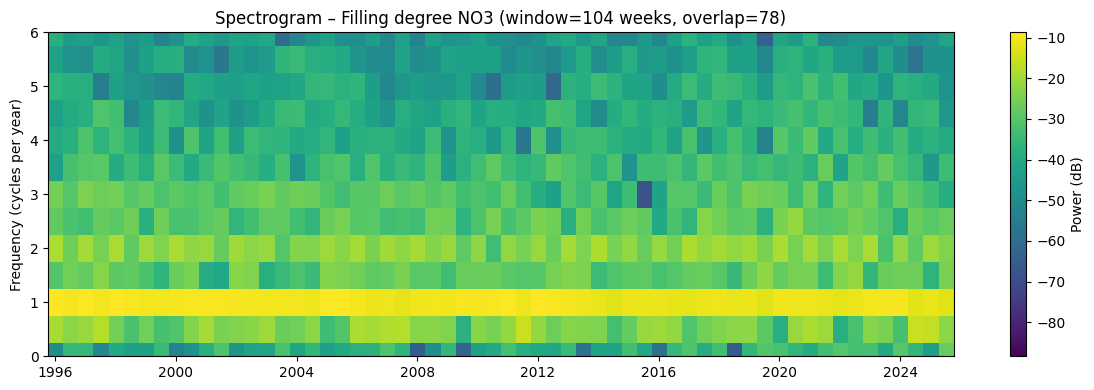

In [15]:
fig = plot_spectrogram(filling_no3, label="Filling degree NO3")

**Interpretation:** The dominant band at 1 cycle per year is the annual
cycle of snowmelt in spring and filling in summer/autumn. Weaker bands
at 2 and 3 cycles per year are harmonics, caused by the cycle not being
a pure sine wave (slow drawdown in winter, fast filling in spring).
Above about 5 cycles per year the content is mostly noise. The annual
band is stable over the whole period, while its strength varies
somewhat between years.